In [ ]:
# 🌸 Supervised Learning on the Iris Dataset
This notebook demonstrates a basic supervised learning workflow using the **Iris dataset**. We will load the dataset, explore it briefly, train machine learning models, and evaluate their performance.

This project is a beginner-friendly example to understand supervised classification with scikit-learn.

In [ ]:
# Step 1: Load the Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
# Step 2: Explore the Dataset

In [2]:
from sklearn.datasets import load_iris
iris_data = load_iris()

In [4]:
print(iris_data.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [6]:
df = pd.DataFrame(iris_data.data)
df.columns = iris_data.feature_names
df.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
5,5.4,3.9,1.7,0.4
6,4.6,3.4,1.4,0.3
7,5.0,3.4,1.5,0.2
8,4.4,2.9,1.4,0.2
9,4.9,3.1,1.5,0.1


In [10]:
df['Species'] = iris_data.target
df.head(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [11]:
df.tail(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2
149,5.9,3.0,5.1,1.8,2


In [12]:
df['Species'].unique()

array([0, 1, 2])

In [25]:
print("Species name: ", iris_data['target_names'])

Species name:  ['setosa' 'versicolor' 'virginica']


In [26]:
df.shape

(150, 5)

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [28]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Species              0
dtype: int64

In [29]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [30]:
df['Species'].value_counts()

Species
0    50
1    50
2    50
Name: count, dtype: int64

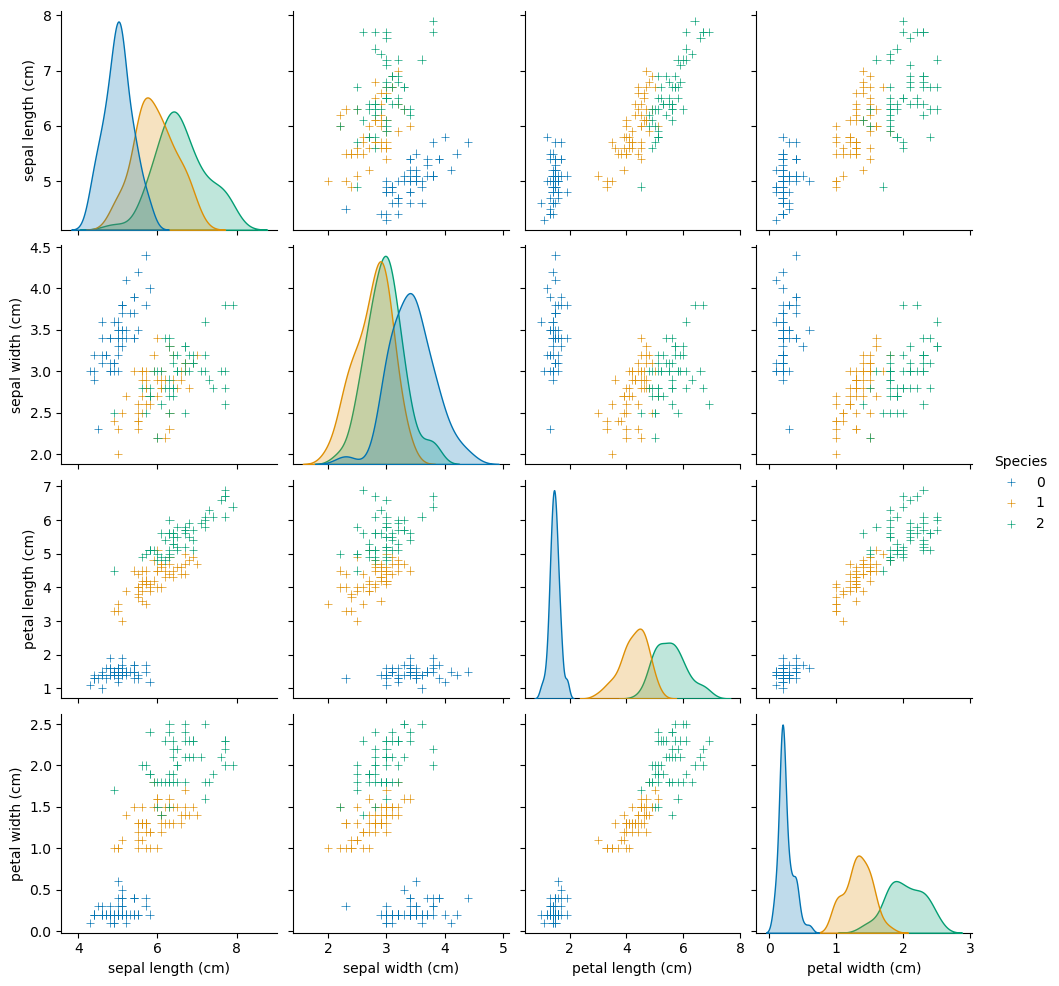

In [35]:
sns.pairplot(df, hue = 'Species', markers = '+', palette = 'colorblind')
plt.show()

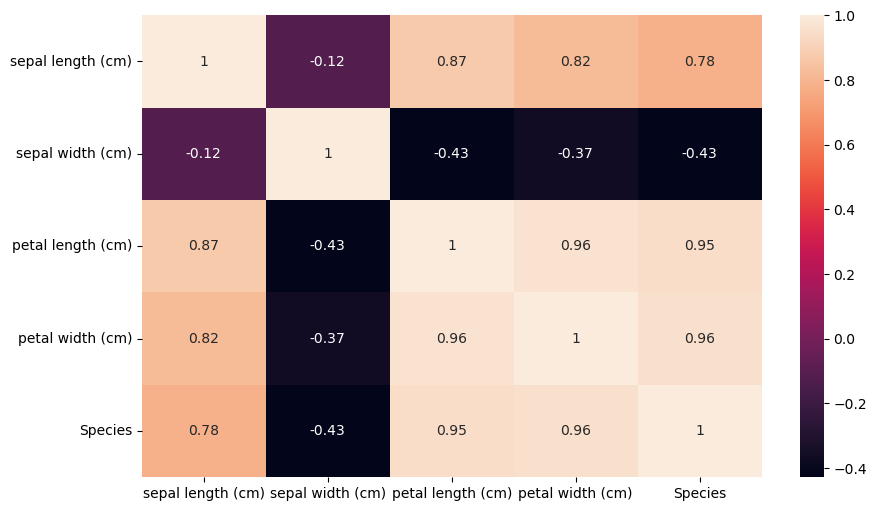

In [38]:
plt.figure(figsize = (10,6))
sns.heatmap(df.corr(), annot = True)
plt.show()

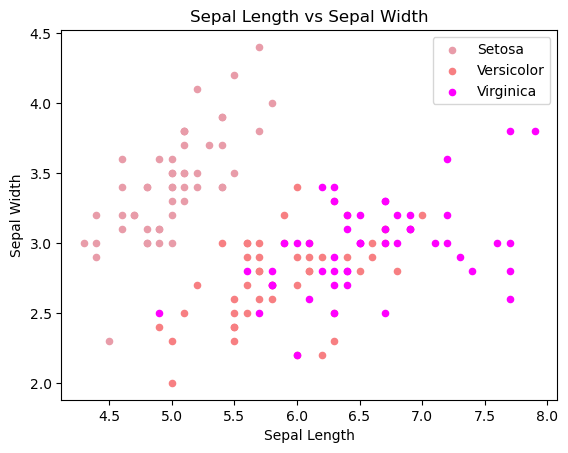

In [51]:
fig = df[df.Species==0].plot(kind='scatter', x="sepal length (cm)", y = "sepal width (cm)", color="#E89CA9", label='Setosa')
df[df.Species==1].plot(kind='scatter', x="sepal length (cm)", y = "sepal width (cm)", color="#F77F82", label='Versicolor', ax=fig)
df[df.Species==2].plot(kind='scatter', x="sepal length (cm)", y = "sepal width (cm)", color='magenta', label='Virginica', ax=fig)
fig.set_xlabel("Sepal Length")
fig.set_ylabel("Sepal Width")
fig.set_title("Sepal Length vs Sepal Width")
plt.show()

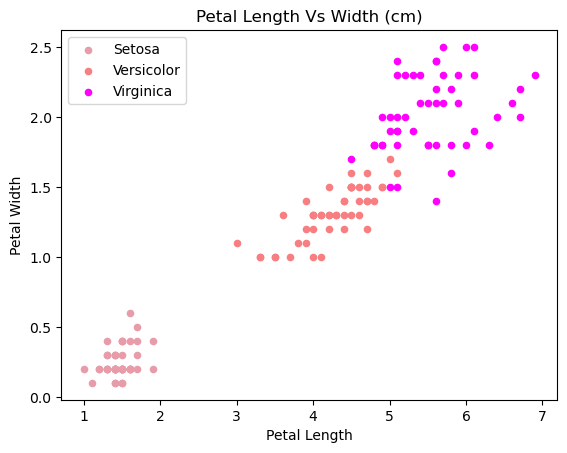

In [55]:
fig = df[df.Species==0].plot(kind='scatter', x="petal length (cm)", y = "petal width (cm)", color="#E89CA9", label='Setosa')
df[df.Species==1].plot(kind='scatter', x="petal length (cm)", y = "petal width (cm)", color="#F77F82", label='Versicolor', ax=fig)
df[df.Species==2].plot(kind='scatter', x="petal length (cm)", y = "petal width (cm)", color='magenta', label='Virginica', ax=fig)
fig.set_xlabel("Petal Length")
fig.set_ylabel("Petal Width")
fig.set_title("Petal Length Vs Width (cm)")
plt.show()

In [66]:
#sns.violinplot(x="Species",y='sepal length (cm)', data=df )

<Axes: xlabel='Species', ylabel='sepal length (cm)'>

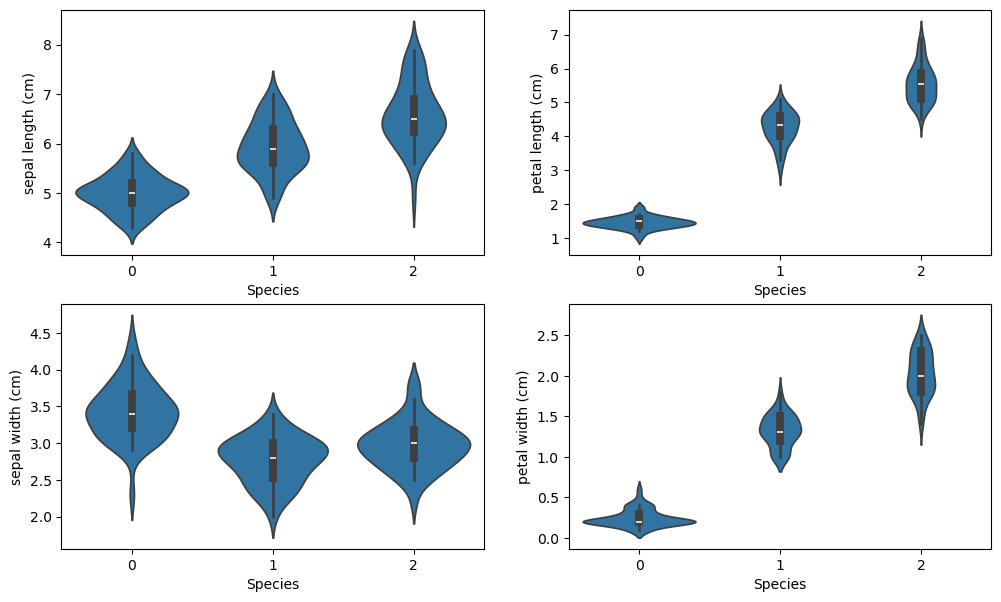

In [69]:
plt.figure(figsize = (12,7))
plt.subplot(2,2,1)
sns.violinplot(x="Species", y='sepal length (cm)', data=df)
plt.subplot(2,2,2)
sns.violinplot(x="Species", y='petal length (cm)', data=df)
plt.subplot(2,2,3)
sns.violinplot(x="Species", y='sepal width (cm)', data=df)
plt.subplot(2,2,4)
sns.violinplot(x="Species", y='petal width (cm)', data=df)
plt.show()

In [ ]:
# Step 4: Train Supervised Learning Models

In [70]:
X = df.drop('Species', axis = 1)
y = df["Species"]

In [71]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3, random_state=42)

In [72]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (105, 4)
X_test: (45, 4)
y_train: (105,)
y_test: (45,)


In [73]:
dtree = DecisionTreeClassifier()
dtree.fit(X_train, y_train)
dtree_pred = dtree.predict(X_test)
dtree_acc = accuracy_score(dtree_pred, y_test)
print("Test accuracy: {:.2f}%".format(dtree_acc*100))

Test accuracy: 100.00%


In [ ]:
# Step 5: Model Evaluation

In [74]:
print(classification_report(y_test, dtree_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



In [75]:
print(confusion_matrix(y_test, dtree_pred))

[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]


In [ ]:
# Step 6: Model Visualization

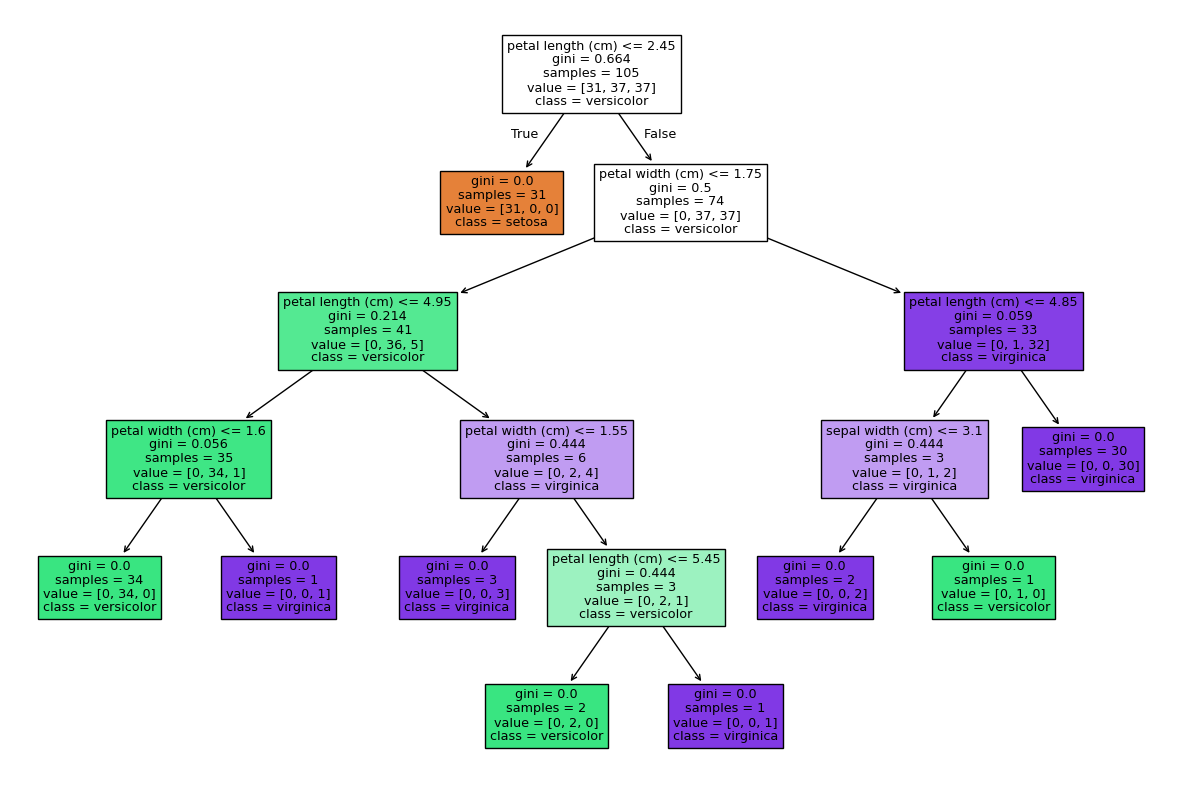

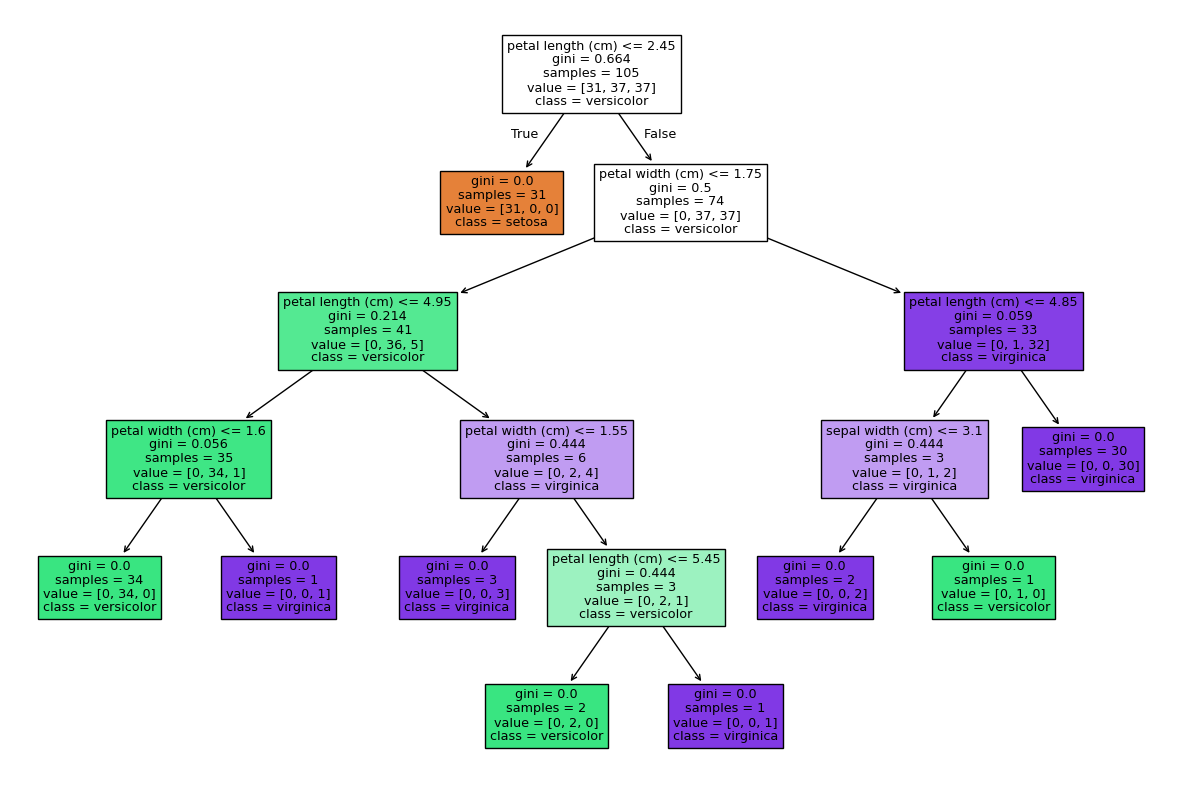

In [77]:
plt.figure(figsize=(15,10))
plot_tree(dtree, feature_names=iris_data.feature_names, class_names= iris_data['target_names'], filled=True)
plt.show()

In [ ]:
# Step 7: Model Training

In [79]:
knn_model = KNeighborsClassifier(n_neighbors=3)
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)
knn_acc = accuracy_score(knn_pred, y_test)
print("Test accuracy: {:.2f}%".format(knn_acc*100))

Test accuracy: 100.00%


In [ ]:
# Step 8: Model Evaluation

In [80]:
print(classification_report(y_test, knn_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      1.00      1.00        13
           2       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



In [81]:
print(confusion_matrix(y_test, knn_pred))

[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]


In [82]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:
# Step 9: Model Prediction Testing

In [93]:
sl = float(input("Enter sepal length (cm): "))
sw = float(input("Enter sepal width (cm): "))
pl = float(input("Enter petal length (cm): "))
pw = float(input("Enter petal width (cm): "))

data = [[sl, sw, pl, pw]]
new_df = pd.DataFrame(data, columns=iris_data.feature_names)
print(new_df)

value_pred = dtree.predict(new_df)
print("Predicted species by Decision Tree:", iris_data.target_names[value_pred][0])

value_pred = knn_model.predict(new_df)
print("Predicted species by KNN:", iris_data.target_names[value_pred][0])


Enter sepal length (cm):  3.2
Enter sepal width (cm):  2.7
Enter petal length (cm):  5.5
Enter petal width (cm):  2.3


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                3.2               2.7                5.5               2.3
Predicted species by Decision Tree: virginica
Predicted species by KNN: virginica


In [ ]:
# Both the models' performance aligns as promised.